Lab Assignment - 8
Decision Trees and Support Vector Machines

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [11]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

columns = ["variance", "skewness", "curtosis", "entropy", "class"]

df = pd.read_csv(url, header=None, names=columns)

print("Dataset shape:", df.shape)
print(df.head())
print(df["class"].value_counts())

Dataset shape: (1372, 5)
   variance  skewness  curtosis  entropy  class
0   3.62160    8.6661   -2.8073 -0.44699      0
1   4.54590    8.1674   -2.4586 -1.46210      0
2   3.86600   -2.6383    1.9242  0.10645      0
3   3.45660    9.5228   -4.0112 -3.59440      0
4   0.32924   -4.4552    4.5718 -0.98880      0
class
0    762
1    610
Name: count, dtype: int64


In [12]:
# All four features
X = df[["variance", "skewness", "curtosis", "entropy"]].values
y = df["class"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Two features for 2D decision-boundary plots
X_two = df[["variance", "skewness"]].values

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_two, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Four-feature training data:", X_train.shape)
print("Four-feature testing data:", X_test.shape)
print("Two-feature training data:", X_train2.shape)

Four-feature training data: (1097, 4)
Four-feature testing data: (275, 4)
Two-feature training data: (1097, 2)


PART A Decision Tree from Scratch

In [13]:
def gini(y):
    if len(y) == 0:
        return 0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy(y):
    if len(y) == 0:
        return 0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


In [14]:
print("Gini:", gini(np.array([0, 0, 1, 1])))
print("Entropy:", entropy(np.array([0, 0, 1, 1])))

Gini: 0.5
Entropy: 1.0


finding the best feature and threshold

In [15]:
def best_split(X, y, criterion="gini"):

    if criterion == "gini":
        impurity = gini
    else:
        impurity = entropy

    best_gain = 0
    best_feature = None
    best_threshold = None

    for feature in range(X.shape[1]):

        # Try thresholds between selected feature values
        values = np.unique(X[:, feature])

        if len(values) > 30:
            values = np.percentile(values, np.linspace(0, 100, 30))

        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:

            left = X[:, feature] <= threshold
            right = X[:, feature] > threshold

            if np.sum(left) == 0 or np.sum(right) == 0:
                continue

            y_left = y[left]
            y_right = y[right]

            parent_impurity = impurity(y)

            child_impurity = (
                len(y_left) / len(y) * impurity(y_left)
                + len(y_right) / len(y) * impurity(y_right)
            )

            gain = parent_impurity - child_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_gain

manual decision tree

In [16]:
class ManualTree:

    def __init__(self, criterion="gini", max_depth=5):
        self.criterion = criterion
        self.max_depth = max_depth
        self.tree = None

    def fit(self, X, y):
        self.tree = self.build_tree(X, y, 0)

    def build_tree(self, X, y, depth):

        classes, counts = np.unique(y, return_counts=True)
        prediction = classes[np.argmax(counts)]

        node = {"prediction": prediction}

        if len(classes) == 1 or depth >= self.max_depth:
            return node

        feature, threshold, gain = best_split(
            X, y, self.criterion
        )

        if feature is None:
            return node

        left = X[:, feature] <= threshold
        right = X[:, feature] > threshold

        node["feature"] = feature
        node["threshold"] = threshold

        node["left"] = self.build_tree(
            X[left], y[left], depth + 1
        )

        node["right"] = self.build_tree(
            X[right], y[right], depth + 1
        )

        return node

    def predict_one(self, row, node):

        if "feature" not in node:
            return node["prediction"]

        if row[node["feature"]] <= node["threshold"]:
            return self.predict_one(row, node["left"])

        return self.predict_one(row, node["right"])

    def predict(self, X):
        return np.array([
            self.predict_one(row, self.tree)
            for row in X
        ])

    def show_tree(self, node=None, depth=0):

        if node is None:
            node = self.tree

        if "feature" not in node:
            print("  " * depth, "Predict class:", node["prediction"])
            return

        names = ["variance", "skewness"]

        print(
            "  " * depth,
            names[node["feature"]],
            "<=",
            round(node["threshold"], 3)
        )

        self.show_tree(node["left"], depth + 1)
        self.show_tree(node["right"], depth + 1)

In [17]:
manual_tree = ManualTree(
    criterion="gini",
    max_depth=5
)

manual_tree.fit(X_train2, y_train2)

manual_pred = manual_tree.predict(X_test2)

sk_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

sk_tree.fit(X_train2, y_train2)

sk_pred = sk_tree.predict(X_test2)

print("Manual Tree Accuracy:",
      accuracy_score(y_test2, manual_pred))

print("Scikit-learn Tree Accuracy:",
      accuracy_score(y_test2, sk_pred))

print("\nManual Tree Rules:")
manual_tree.show_tree()

Manual Tree Accuracy: 0.9090909090909091
Scikit-learn Tree Accuracy: 0.9309090909090909

Manual Tree Rules:
 variance <= 0.769
   skewness <= 6.039
     variance <= -0.166
       variance <= -0.484
         skewness <= 0.042
           Predict class: 1
           Predict class: 1
         skewness <= 3.692
           Predict class: 1
           Predict class: 0
       skewness <= 0.057
         variance <= -0.031
           Predict class: 0
           Predict class: 1
         variance <= 0.364
           Predict class: 1
           Predict class: 1
     variance <= -3.837
       variance <= -4.433
         Predict class: 1
         variance <= -4.255
           Predict class: 0
           Predict class: 1
       Predict class: 0
   variance <= 1.801
     skewness <= 4.844
       skewness <= 0.581
         skewness <= 0.138
           Predict class: 0
           Predict class: 0
         skewness <= 3.32
           Predict class: 0
           Predict class: 1
       Predict class: 0
  

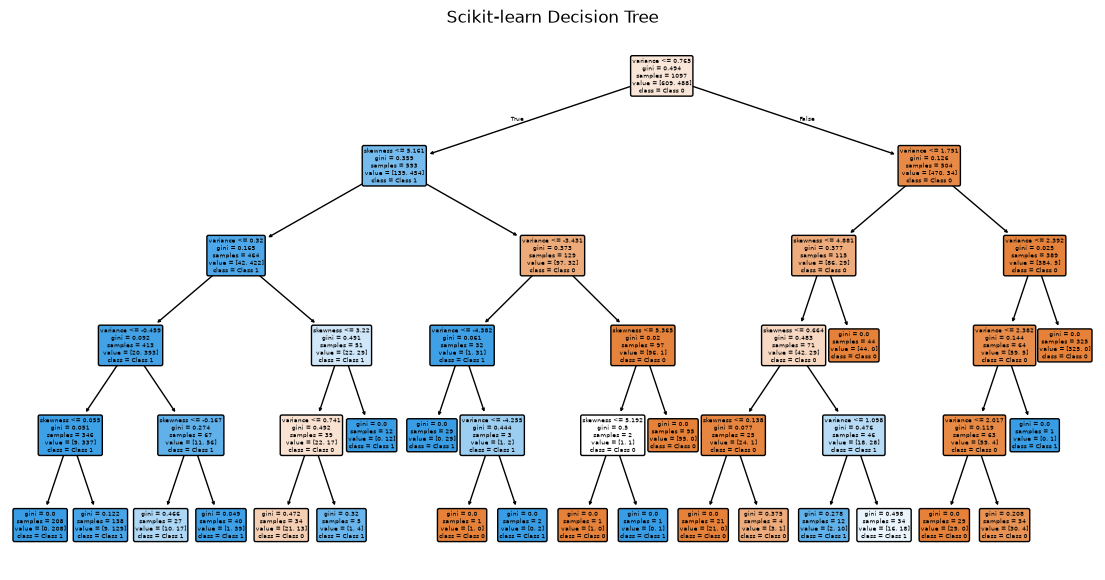

In [18]:
plt.figure(figsize=(14, 7))

plot_tree(
    sk_tree,
    feature_names=["variance", "skewness"],
    class_names=["Class 0", "Class 1"],
    filled=True,
    rounded=True
)

plt.title("Scikit-learn Decision Tree")
plt.show()

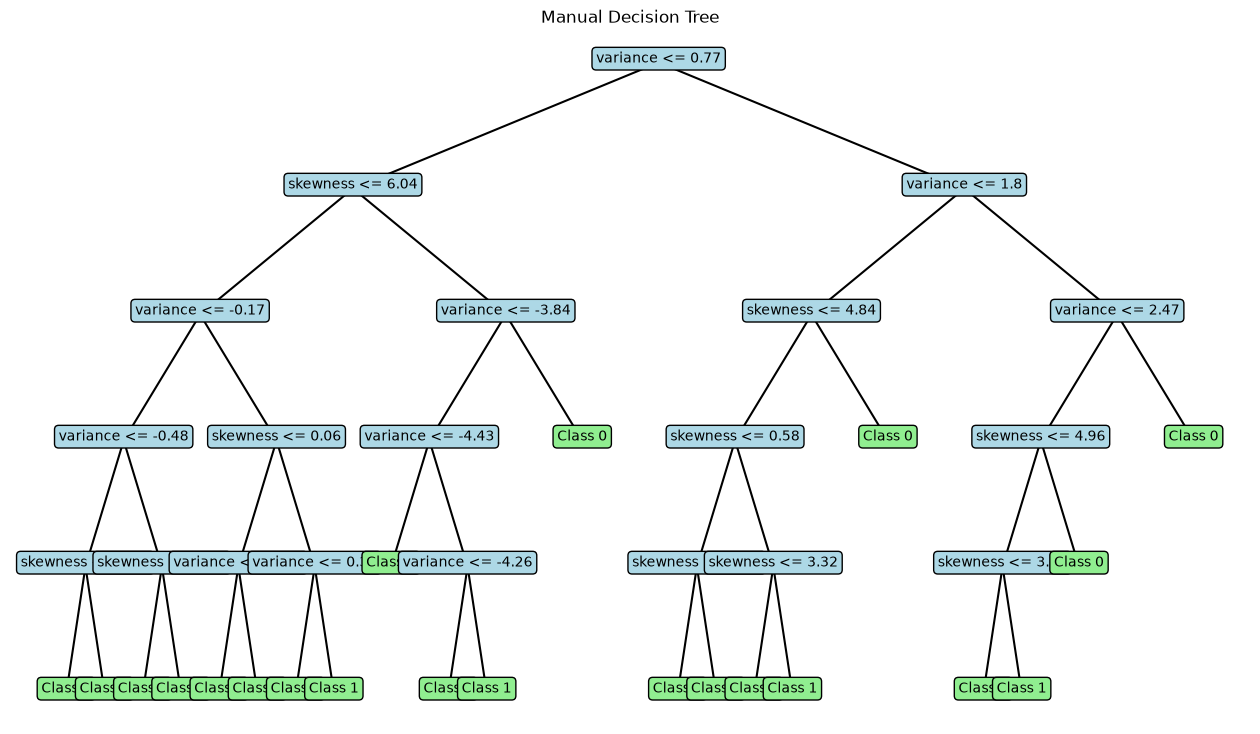

In [19]:
def draw_tree(node, x, y, width, depth=0):

    if "feature" not in node:
        plt.text(
            x, y, "Class " + str(node["prediction"]),
            ha="center",
            bbox=dict(boxstyle="round", facecolor="lightgreen")
        )
        return

    names = ["variance", "skewness"]

    plt.text(
        x, y,
        names[node["feature"]] + " <= " +
        str(round(node["threshold"], 2)),
        ha="center",
        bbox=dict(boxstyle="round", facecolor="lightblue")
    )

    left_x = x - width
    right_x = x + width
    child_y = y - 1

    plt.plot([x, left_x], [y, child_y], "k-")
    plt.plot([x, right_x], [y, child_y], "k-")

    draw_tree(node["left"], left_x, child_y, width / 2, depth + 1)
    draw_tree(node["right"], right_x, child_y, width / 2, depth + 1)


plt.figure(figsize=(16, 9))
plt.axis("off")
draw_tree(manual_tree.tree, 0, 0, 4)
plt.title("Manual Decision Tree")
plt.show()

decision boundary plots

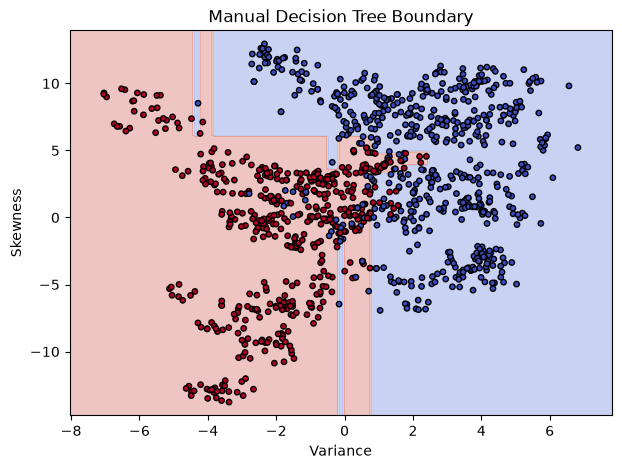

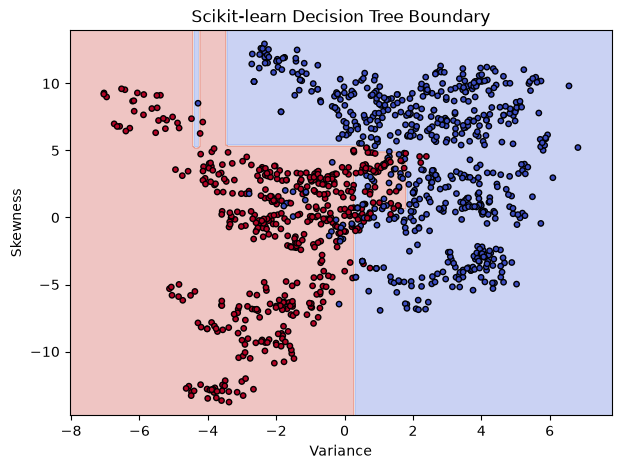

In [20]:
def plot_boundary(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(xx, yy, predictions, alpha=0.3, cmap="coolwarm")
    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", s=15
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.show()


plot_boundary(
    manual_tree, X_train2, y_train2,
    "Manual Decision Tree Boundary"
)

plot_boundary(
    sk_tree, X_train2, y_train2,
    "Scikit-learn Decision Tree Boundary"
)

Comparing

In [22]:
for criterion in ["gini", "entropy"]:

    for depth in [2, 5, 10]:

        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        model.fit(X_train2, y_train2)
        pred = model.predict(X_test2)

        print(
            "Criterion:", criterion,
            "Depth:", depth,
            "Accuracy:", round(
                accuracy_score(y_test2, pred), 4
            )
        )

Criterion: gini Depth: 2 Accuracy: 0.8764
Criterion: gini Depth: 5 Accuracy: 0.9309
Criterion: gini Depth: 10 Accuracy: 0.9236
Criterion: entropy Depth: 2 Accuracy: 0.8764
Criterion: entropy Depth: 5 Accuracy: 0.9345
Criterion: entropy Depth: 10 Accuracy: 0.9309


PART B - Linear SVM from Scratch

In [33]:
class ManualSVM:

    def __init__(self, C=1.0, learning_rate=0.0001, iterations=5000):
        self.C = C
        self.learning_rate = learning_rate
        self.iterations = iterations

    def fit(self, X, y):

        # Standardize using training data only
        self.mean = X.mean(axis=0)
        self.std = X.std(axis=0)
        self.std[self.std == 0] = 1

        X = (X - self.mean) / self.std

        # Convert labels: 0 -> -1, 1 -> +1
        y = np.where(y == 1, 1, -1)

        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []

        for i in range(self.iterations):

            # Calculate signed margins
            margins = y * (X @ self.w + self.b)

            # Points inside or beyond the margin
            wrong = margins < 1

            # Gradient of regularization
            dw = self.w.copy()
            db = 0.0

            # Gradient of hinge loss
            if np.any(wrong):
                dw -= self.C * np.sum(
                    y[wrong, None] * X[wrong], axis=0
                )

                db -= self.C * np.sum(y[wrong])

            # Gradually reduce learning rate
            rate = self.learning_rate / (1 + 0.001 * i)

            self.w -= rate * dw
            self.b -= rate * db

            # Objective: regularization + total hinge loss
            margins = y * (X @ self.w + self.b)

            loss = (
                0.5 * np.sum(self.w ** 2)
                + self.C * np.sum(np.maximum(0, 1 - margins))
            )

            self.loss_history.append(loss)

    def decision_function(self, X):
        X = (X - self.mean) / self.std
        return X @ self.w + self.b

    def predict(self, X):
        scores = self.decision_function(X)
        return np.where(scores >= 0, 1, 0)

In [34]:
manual_svm = ManualSVM(
    C=1.0,
    learning_rate=0.0001,
    iterations=5000
)

manual_svm.fit(X_train2, y_train2)

manual_svm_pred = manual_svm.predict(X_test2)

# Scikit-learn Linear SVM
scaler2 = StandardScaler()

X_train2_scaled = scaler2.fit_transform(X_train2)
X_test2_scaled = scaler2.transform(X_test2)

sk_svm = SVC(kernel="linear", C=1.0)

sk_svm.fit(X_train2_scaled, y_train2)

sk_svm_pred = sk_svm.predict(X_test2_scaled)

print(
    "Manual SVM Accuracy:",
    accuracy_score(y_test2, manual_svm_pred)
)

print("Scikit-learn SVM Accuracy:",
      accuracy_score(y_test2, sk_svm_pred))

Manual SVM Accuracy: 0.8763636363636363
Scikit-learn SVM Accuracy: 0.8763636363636363


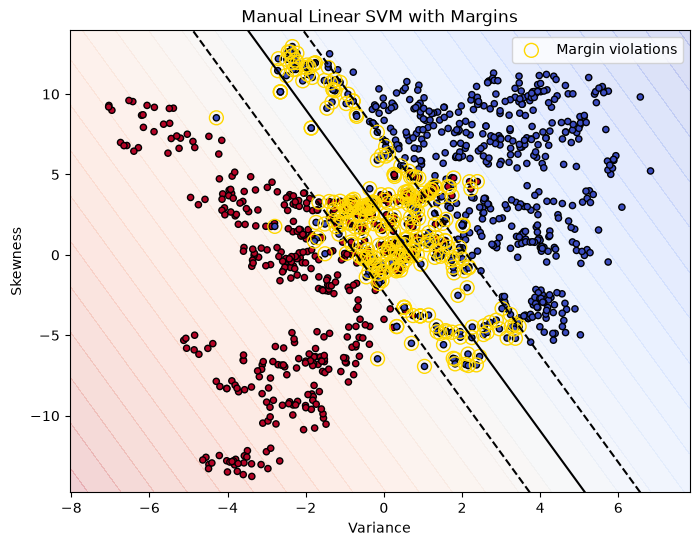

Margin-violating points: 315


In [35]:
def plot_manual_svm(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    scores = model.decision_function(grid).reshape(xx.shape)

    # Find points that violate the margin
    X_scaled = (X - model.mean) / model.std
    y_signed = np.where(y == 1, 1, -1)

    margins = y_signed * (X_scaled @ model.w + model.b)
    violations = margins < 1

    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, scores, levels=30, cmap="coolwarm", alpha=0.2)

    # -1 and +1 are margins; 0 is the separating line
    plt.contour(
        xx, yy, scores,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"]
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", s=20
    )

    plt.scatter(
        X[violations, 0],
        X[violations, 1],
        facecolors="none",
        edgecolors="gold",
        s=100,
        label="Margin violations"
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.legend()
    plt.show()

    print("Margin-violating points:", np.sum(violations))


plot_manual_svm(
    manual_svm,
    X_train2,
    y_train2,
    "Manual Linear SVM with Margins"
)

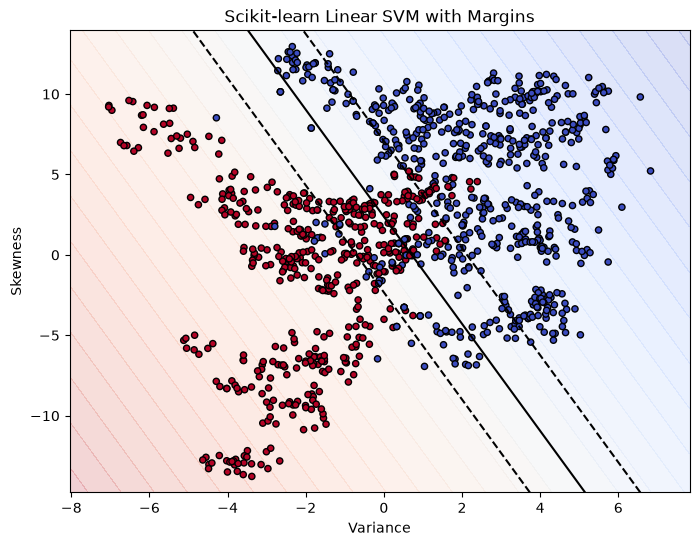

In [36]:
def plot_sklearn_svm(model, scaler, X, y, title):

    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_scaled = scaler.transform(grid)

    scores = model.decision_function(grid_scaled).reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(xx, yy, scores, levels=30, cmap="coolwarm", alpha=0.2)

    plt.contour(
        xx, yy, scores,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"]
    )

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", s=20
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.show()


plot_sklearn_svm(
    sk_svm, scaler2, X_train2, y_train2,
    "Scikit-learn Linear SVM with Margins"
)

In [37]:
for C in [0.1, 1, 10]:

    for rate in [0.001, 0.01]:

        for iterations in [1000, 2000]:

            model = ManualSVM(
                C=C,
                learning_rate=rate,
                iterations=iterations
            )

            model.fit(X_train2, y_train2)
            pred = model.predict(X_test2)

            print(
                "C:", C,
                "| Learning rate:", rate,
                "| Iterations:", iterations,
                "| Accuracy:", round(
                    accuracy_score(y_test2, pred), 4
                )
            )

C: 0.1 | Learning rate: 0.001 | Iterations: 1000 | Accuracy: 0.8836
C: 0.1 | Learning rate: 0.001 | Iterations: 2000 | Accuracy: 0.8836
C: 0.1 | Learning rate: 0.01 | Iterations: 1000 | Accuracy: 0.8836
C: 0.1 | Learning rate: 0.01 | Iterations: 2000 | Accuracy: 0.8836
C: 1 | Learning rate: 0.001 | Iterations: 1000 | Accuracy: 0.8764
C: 1 | Learning rate: 0.001 | Iterations: 2000 | Accuracy: 0.8764
C: 1 | Learning rate: 0.01 | Iterations: 1000 | Accuracy: 0.8764
C: 1 | Learning rate: 0.01 | Iterations: 2000 | Accuracy: 0.8764
C: 10 | Learning rate: 0.001 | Iterations: 1000 | Accuracy: 0.88
C: 10 | Learning rate: 0.001 | Iterations: 2000 | Accuracy: 0.8764
C: 10 | Learning rate: 0.01 | Iterations: 1000 | Accuracy: 0.8436
C: 10 | Learning rate: 0.01 | Iterations: 2000 | Accuracy: 0.7018


PART C - Kernel SVM and Nonlinear Boundaries

In [38]:
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.2,
    random_state=42
)

X_moon_train, X_moon_test, y_moon_train, y_moon_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=42,
    stratify=y_moons
)

moon_scaler = StandardScaler()

X_moon_train_scaled = moon_scaler.fit_transform(X_moon_train)
X_moon_test_scaled = moon_scaler.transform(X_moon_test)

linear_model = SVC(kernel="linear", C=1)
poly_model = SVC(kernel="poly", degree=3, C=1)
rbf_model = SVC(kernel="rbf", C=1)

models = {
    "Linear": linear_model,
    "Polynomial": poly_model,
    "RBF": rbf_model
}

for name, model in models.items():

    model.fit(X_moon_train_scaled, y_moon_train)

    pred = model.predict(X_moon_test_scaled)

    print("\n", name, "SVM")
    print("Accuracy:", accuracy_score(y_moon_test, pred))
    print("Precision:", precision_score(y_moon_test, pred, zero_division=0))
    print("Recall:", recall_score(y_moon_test, pred, zero_division=0))
    print("F1-score:", f1_score(y_moon_test, pred, zero_division=0))


 Linear SVM
Accuracy: 0.86
Precision: 0.8461538461538461
Recall: 0.88
F1-score: 0.8627450980392157

 Polynomial SVM
Accuracy: 0.85
Precision: 0.8571428571428571
Recall: 0.84
F1-score: 0.8484848484848485

 RBF SVM
Accuracy: 0.99
Precision: 1.0
Recall: 0.98
F1-score: 0.98989898989899


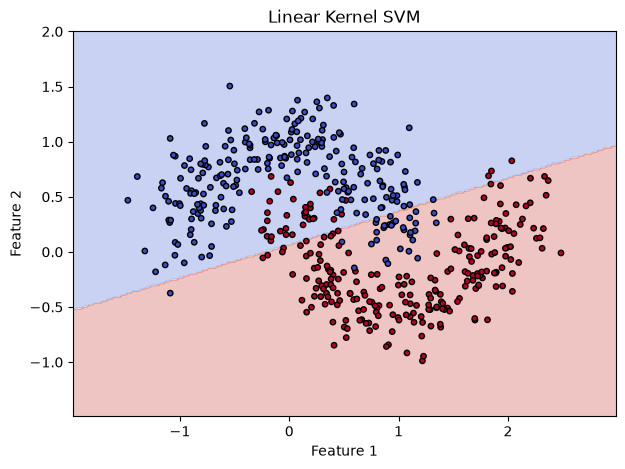

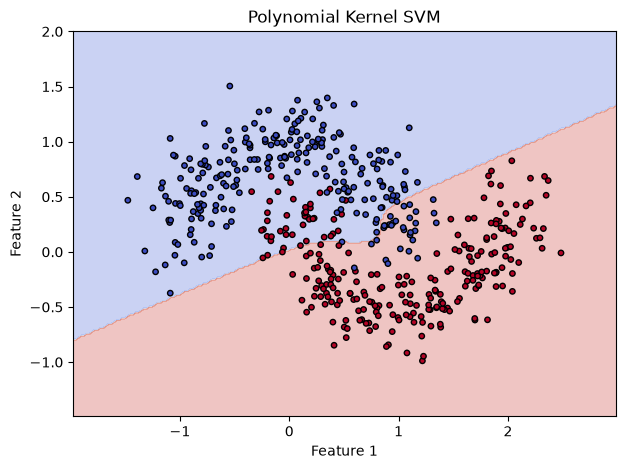

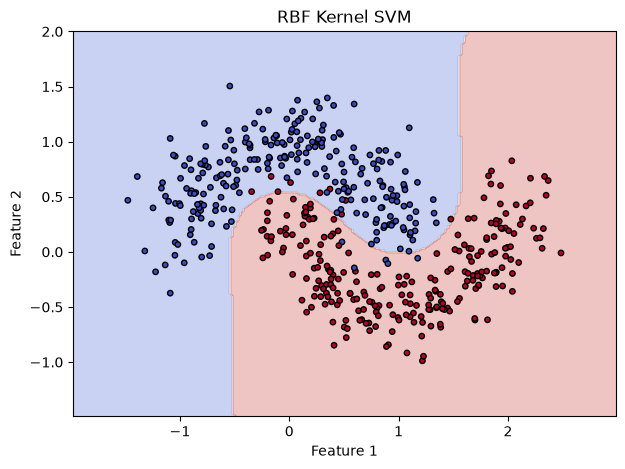

In [39]:
def plot_kernel(model, X, y, title):

    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_scaled = moon_scaler.transform(grid)

    predictions = model.predict(grid_scaled).reshape(xx.shape)

    plt.figure(figsize=(7, 5))

    plt.contourf(xx, yy, predictions, alpha=0.3, cmap="coolwarm")

    plt.scatter(
        X[:, 0], X[:, 1],
        c=y, cmap="coolwarm",
        edgecolors="black", s=15
    )

    plt.title(title)
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.show()


plot_kernel(linear_model, X_moons, y_moons, "Linear Kernel SVM")
plot_kernel(poly_model, X_moons, y_moons, "Polynomial Kernel SVM")
plot_kernel(rbf_model, X_moons, y_moons, "RBF Kernel SVM")

PART D - Final Comparison

training manual and Scikit-learn Decision Trees, manual and Scikit-learn linear SVMs, and an RBF SVM using all four features.

In [40]:
# 1. Manual Decision Tree
manual_tree4 = ManualTree(criterion="gini", max_depth=5)

start = time.time()
manual_tree4.fit(X_train, y_train)
manual_tree_time = time.time() - start

start = time.time()
manual_tree_pred = manual_tree4.predict(X_test)
manual_tree_predict_time = time.time() - start


# 2. Scikit-learn Decision Tree
sk_tree4 = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

start = time.time()
sk_tree4.fit(X_train, y_train)
sk_tree_time = time.time() - start

start = time.time()
sk_tree_pred = sk_tree4.predict(X_test)
sk_tree_predict_time = time.time() - start


# 3. Manual Linear SVM
manual_svm4 = ManualSVM(
    C=1,
    learning_rate=0.01,
    iterations=2000
)

start = time.time()
manual_svm4.fit(X_train, y_train)
manual_svm_time = time.time() - start

start = time.time()
manual_svm_pred = manual_svm4.predict(X_test)
manual_svm_predict_time = time.time() - start


# Scale the data for scikit-learn SVMs
scaler4 = StandardScaler()

X_train_scaled = scaler4.fit_transform(X_train)
X_test_scaled = scaler4.transform(X_test)


# 4. Scikit-learn Linear SVM
sk_linear4 = SVC(kernel="linear", C=1)

start = time.time()
sk_linear4.fit(X_train_scaled, y_train)
sk_linear_time = time.time() - start

start = time.time()
sk_linear_pred = sk_linear4.predict(X_test_scaled)
sk_linear_predict_time = time.time() - start


# 5. Scikit-learn RBF SVM
sk_rbf4 = SVC(kernel="rbf", C=1)

start = time.time()
sk_rbf4.fit(X_train_scaled, y_train)
sk_rbf_time = time.time() - start

start = time.time()
sk_rbf_pred = sk_rbf4.predict(X_test_scaled)
sk_rbf_predict_time = time.time() - start

comparing

In [41]:
def evaluate_model(name, y_true, y_pred, train_time, predict_time):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "Training time (s)": train_time,
        "Prediction time (s)": predict_time
    }


results = [
    evaluate_model(
        "Manual Decision Tree", y_test, manual_tree_pred,
        manual_tree_time, manual_tree_predict_time
    ),

    evaluate_model(
        "Scikit-learn Decision Tree", y_test, sk_tree_pred,
        sk_tree_time, sk_tree_predict_time
    ),

    evaluate_model(
        "Manual Linear SVM", y_test, manual_svm_pred,
        manual_svm_time, manual_svm_predict_time
    ),

    evaluate_model(
        "Scikit-learn Linear SVM", y_test, sk_linear_pred,
        sk_linear_time, sk_linear_predict_time
    ),

    evaluate_model(
        "Scikit-learn RBF SVM", y_test, sk_rbf_pred,
        sk_rbf_time, sk_rbf_predict_time
    )
]

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

                     Model  Accuracy  Precision  Recall  F1-score  Training time (s)  Prediction time (s)
      Manual Decision Tree    0.9709     0.9453  0.9918    0.9680             0.1036               0.0006
Scikit-learn Decision Tree    0.9927     0.9839  1.0000    0.9919             0.0035               0.0004
         Manual Linear SVM    0.9745     0.9457  1.0000    0.9721             0.0735               0.0016
   Scikit-learn Linear SVM    0.9745     0.9457  1.0000    0.9721             0.0064               0.0009
      Scikit-learn RBF SVM    1.0000     1.0000  1.0000    1.0000             0.0031               0.0020


In [42]:
print("Scikit-learn Decision Tree depth:", sk_tree4.get_depth())
print("Scikit-learn Decision Tree leaves:", sk_tree4.get_n_leaves())

print("Linear SVM support vectors:",
      np.sum(sk_linear4.n_support_))

print("RBF SVM support vectors:",
      np.sum(sk_rbf4.n_support_))

Scikit-learn Decision Tree depth: 5
Scikit-learn Decision Tree leaves: 20
Linear SVM support vectors: 62
RBF SVM support vectors: 91


The Scikit-learn RBF SVM achieved the best performance, with 100% accuracy, precision, recall and F1-score on the test set. 
The Scikit-learn Decision Tree achieved 99.27% accuracy, while the manual Decision Tree achieved 97.09%.
The manual Linear SVM achieved 97.45% accuracy and matched the reported performance of the Scikit-learn Linear SVM.

The Scikit-learn implementations takes comparatively less time and gets trained faster than the manual implementations.
